In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# --- Adım 1: Veri Seti Oluşturma ---
data = {
    'Surucu_Yasi': [21, 35, 48, 25, 60, 30, 42, 22, 55, 38],
    'Ehliyet_Yili': [2, 15, 25, 5, 40, 10, 20, 2, 35, 12],
    'Arac_Beygir_Gucu': [75, 110, 150, 90, 200, 100, 130, 80, 175, 120],
    'Yillik_Km': [15000, 10000, 8000, 20000, 5000, 12000, 9000, 25000, 7000, 11000],
    'Sigorta_Primi_TL': [12000, 6500, 5000, 15000, 4000, 7000, 5500, 16000, 4500, 6800] # Hedef (y)
}
df = pd.DataFrame(data)

In [2]:
df

,Surucu_Yasi,Ehliyet_Yili,Arac_Beygir_Gucu,Yillik_Km,Sigorta_Primi_TL
0,21,2,75,15000,12000
1,35,15,110,10000,6500
2,48,25,150,8000,5000
3,25,5,90,20000,15000
4,60,40,200,5000,4000
5,30,10,100,12000,7000
6,42,20,130,9000,5500
7,22,2,80,25000,16000
8,55,35,175,7000,4500
9,38,12,120,11000,6800


In [4]:
X = df.drop("Sigorta_Primi_TL",axis=1)
y=df["Sigorta_Primi_TL"]

In [5]:
X_test,X_train,y_test,y_train = train_test_split(X,y,test_size=0.2,random_state=42)

In [6]:
scaler = StandardScaler()

In [7]:
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [8]:
model = LinearRegression()

In [10]:
model.fit(X_train_scaled,y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [11]:
y_pred = model.predict(X_test_scaled)

In [12]:
print(f"\n[ORTA - SİGORTA] Sonuçlar:")
print(f"MAE: {mean_absolute_error(y_test, y_pred):.2f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test, y_pred)):.2f}")
print(f"R2 Score: {r2_score(y_test, y_pred):.2f}")


[ORTA - SİGORTA] Sonuçlar:
MAE: 2166.35
RMSE: 3351.46
R2 Score: 0.42


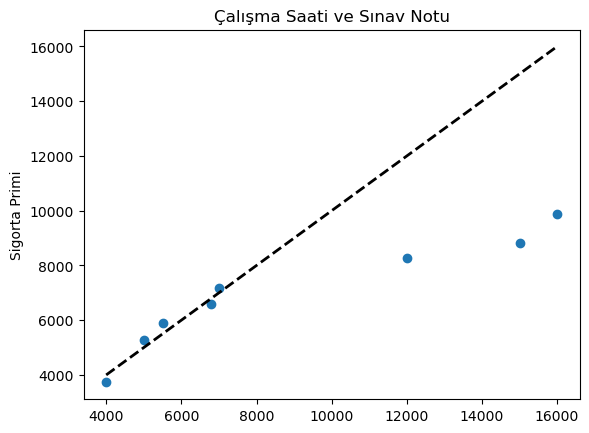

In [16]:
plt.scatter(y_test,y_pred)
plt.xlabel("")
plt.plot([y.min(), y.max()], [y.min(), y.max()], 'k--', lw=2) # İdeal 45 derece çizgisi
plt.ylabel("Sigorta Primi")
plt.title("Çalışma Saati ve Sınav Notu")
plt.show()

In [17]:
residuals = y_test - y_pred


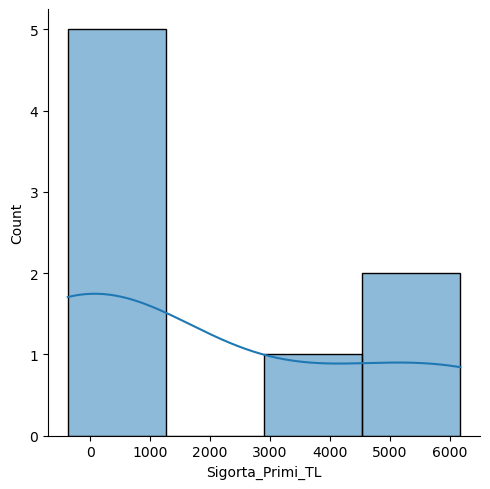

In [18]:
sns.displot(residuals,kde="kde")
plt.show()

In [30]:
yeni = pd.DataFrame({
    'Surucu_Yasi': [28],
    'Ehliyet_Yili': [6],
    'Arac_Beygir_Gucu': [105],
    'Yillik_Km': [14000]
})

In [31]:
tahmin = model.predict(yeni)

/opt/anaconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2742: UserWarning: X has feature names, but LinearRegression was fitted without feature names
  warnings.warn(


In [33]:
print(f"Yeni Sürücü için tahmin edilen sigorta pirimi : {tahmin[0]:.2f}TL")

Yeni Sürücü için tahmin edilen sigorta pirimi : 3470750.00TL
